# PRCP-1018-Bike Rental Demand Prediction

## Project Overview
This project develops a machine learning regression system to estimate the daily number of bike rentals from environmental and seasonal information, using the Capital Bikeshare (Washington D.C.) dataset for 2011-2012.

## Business Objective
Bike rental demand changes with the weather, the season and the day of the week. The objective is to analyze the provided bike-sharing dataset, identify the factors associated with rental demand, compare multiple regression models, and select the best-performing model for predicting daily rental counts.

## Project Tasks
1. Perform a complete exploratory data analysis of the bike-sharing dataset.
2. Build a predictive model for estimating the daily bike rental count (`cnt`).
3. Compare multiple machine learning models and recommend the best model for production.
4. Document the major data challenges and the techniques used to address them.

> **Important:** This model provides an estimate based on historical patterns in the supplied dataset (2011-2012, Washington D.C.). It is not a real-time demand forecast.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

In [2]:
day  = pd.read_csv("day.csv")
hour = pd.read_csv("hour.csv")

print("Day shape :", day.shape)
print("Hour shape:", hour.shape)
day.head()

Day shape : (731, 16)
Hour shape: (17379, 17)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [3]:
day.info()



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB


In [4]:
day.describe()

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


In [5]:
print("Missing values:\n", day.isnull().sum())
print("\nDuplicate rows:", day.duplicated().sum())

Missing values:
 instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

Duplicate rows: 0


**Observations:** The dataset has 731 daily records and 16 columns. There are no missing values or duplicate rows. `dteday` is stored as text and must be converted to datetime. `hum` has a minimum of 0, which needs investigation.

# Data cleaning and preprocessing

In [6]:
df = day.copy()

In [7]:
df["dteday"] = pd.to_datetime(df["dteday"])

In [8]:
df.groupby("season")["mnth"].unique()

season
1      [1, 2, 3, 12]
2       [3, 4, 5, 6]
3       [6, 7, 8, 9]
4    [9, 10, 11, 12]
Name: mnth, dtype: object

In [9]:
season_map  = {1: "Winter", 2: "Spring", 3: "Summer", 4: "Fall"}
weather_map = {1: "Clear", 2: "Mist/Cloudy", 3: "Light Rain/Snow", 4: "Heavy Rain/Snow"}
weekday_map = {0: "Sun", 1: "Mon", 2: "Tue", 3: "Wed", 4: "Thu", 5: "Fri", 6: "Sat"}
month_map   = dict(enumerate(
    ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"], start=1))

df["season_lbl"]  = df["season"].map(season_map)
df["weather_lbl"] = df["weathersit"].map(weather_map)
df["weekday_lbl"] = df["weekday"].map(weekday_map)
df["month_lbl"]   = df["mnth"].map(month_map)
df["year_lbl"]    = df["yr"].map({0: 2011, 1: 2012})

In [10]:
df["temp_c"]    = df["temp"] * 47 - 8      # real temperature in °C
df["atemp_c"]   = df["atemp"] * 66 - 16    # "feels like" temperature in °C
df["hum_pct"]   = df["hum"] * 100          # humidity in %
df["wind_kmph"] = df["windspeed"] * 67     # wind speed

df[["temp_c", "atemp_c", "hum_pct", "wind_kmph"]].describe()

,temp_c,atemp_c,hum_pct,wind_kmph
count,731.000000,731.000000,731.000000,731.000000
mean,15.283085,15.307363,62.789406,12.762576
std,8.603397,10.755438,14.242910,5.192357
min,-5.220871,-10.781406,0.000000,1.500244
25%,7.842925,6.297605,52.000000,9.041650
50%,15.421651,16.124378,62.666700,12.125325
75%,22.804575,24.167732,73.020850,15.625371
max,32.498349,39.499136,97.250000,34.000021


In [11]:
df[df["hum"] == 0][["dteday", "hum", "weather_lbl", "cnt"]]

,dteday,hum,weather_lbl,cnt
68,2011-03-10,0.0,Light Rain/Snow,623


In [12]:
median_hum = df.loc[df["hum"] != 0, "hum"].median()
df.loc[df["hum"] == 0, "hum"] = median_hum
df["hum_pct"] = df["hum"] * 100

# EDA

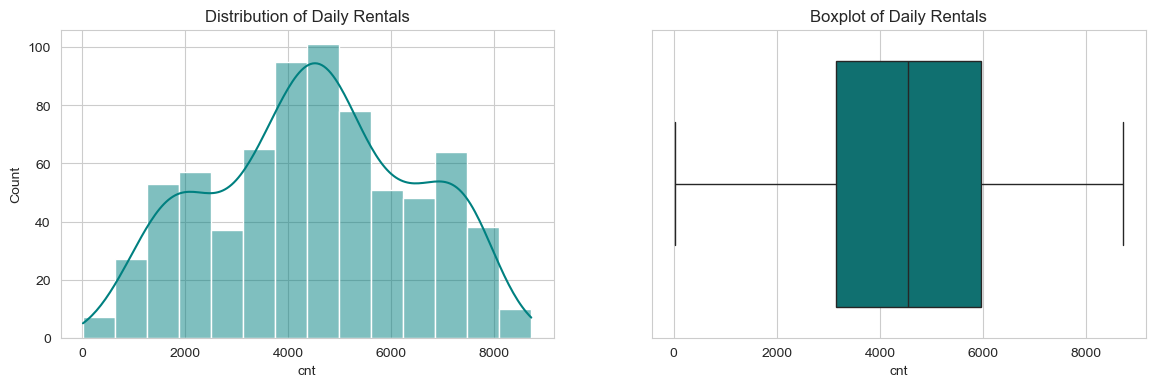

Skewness: -0.047


In [13]:
# Target variable: cnt

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df["cnt"], kde=True, ax=ax[0], color="teal")
sns.boxplot(x=df["cnt"], ax=ax[1], color="teal")
ax[0].set_title("Distribution of Daily Rentals")
ax[1].set_title("Boxplot of Daily Rentals")
plt.show()
print("Skewness:", round(df["cnt"].skew(), 3))

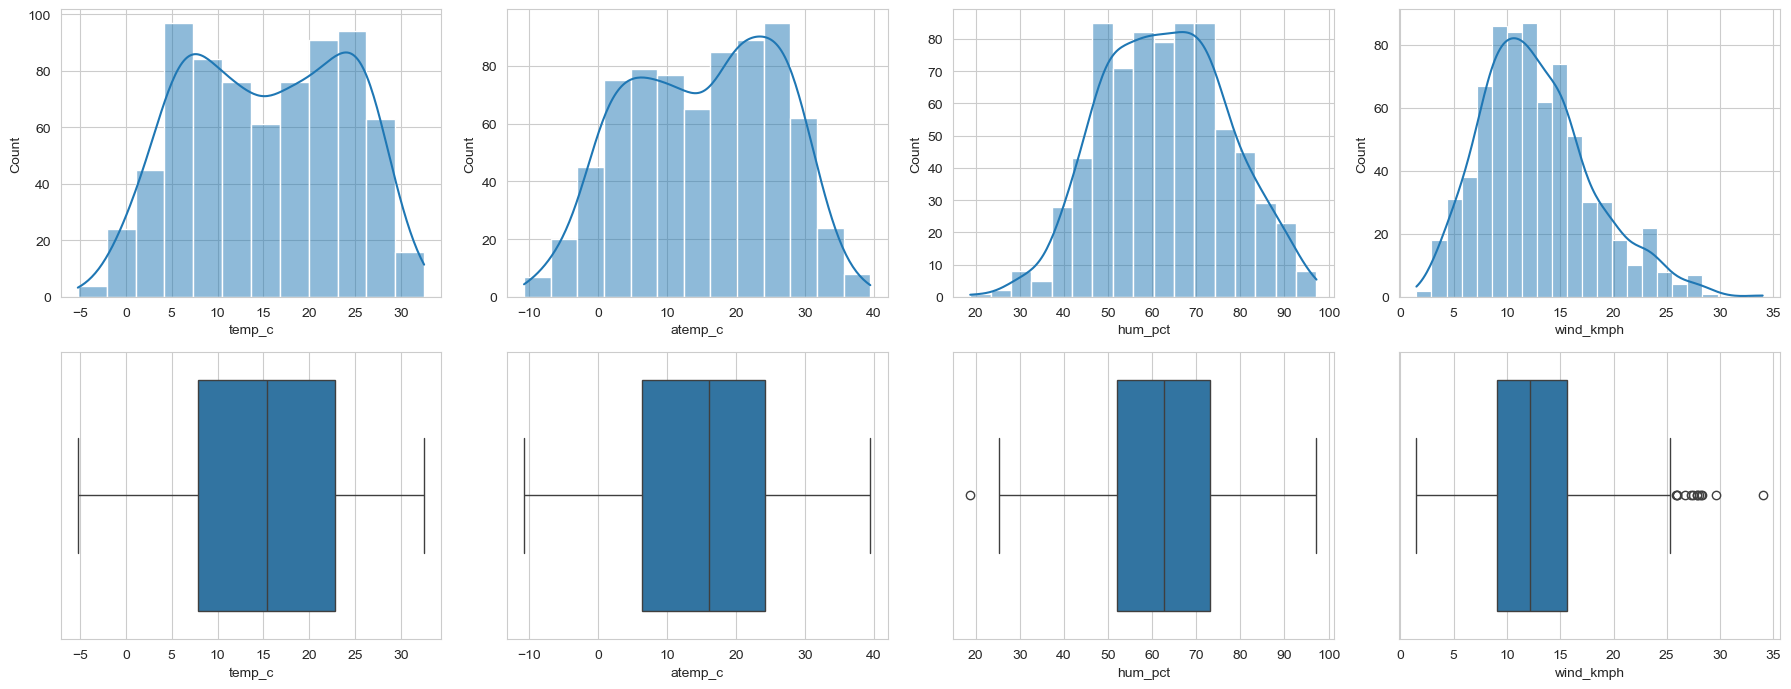

In [14]:
# Weather features (numeric)
cols = ["temp_c", "atemp_c", "hum_pct", "wind_kmph"]
fig, ax = plt.subplots(2, 4, figsize=(18, 7))
for i, c in enumerate(cols):
    sns.histplot(df[c], kde=True, ax=ax[0, i])
    sns.boxplot(x=df[c], ax=ax[1, i])
plt.tight_layout()
plt.show()

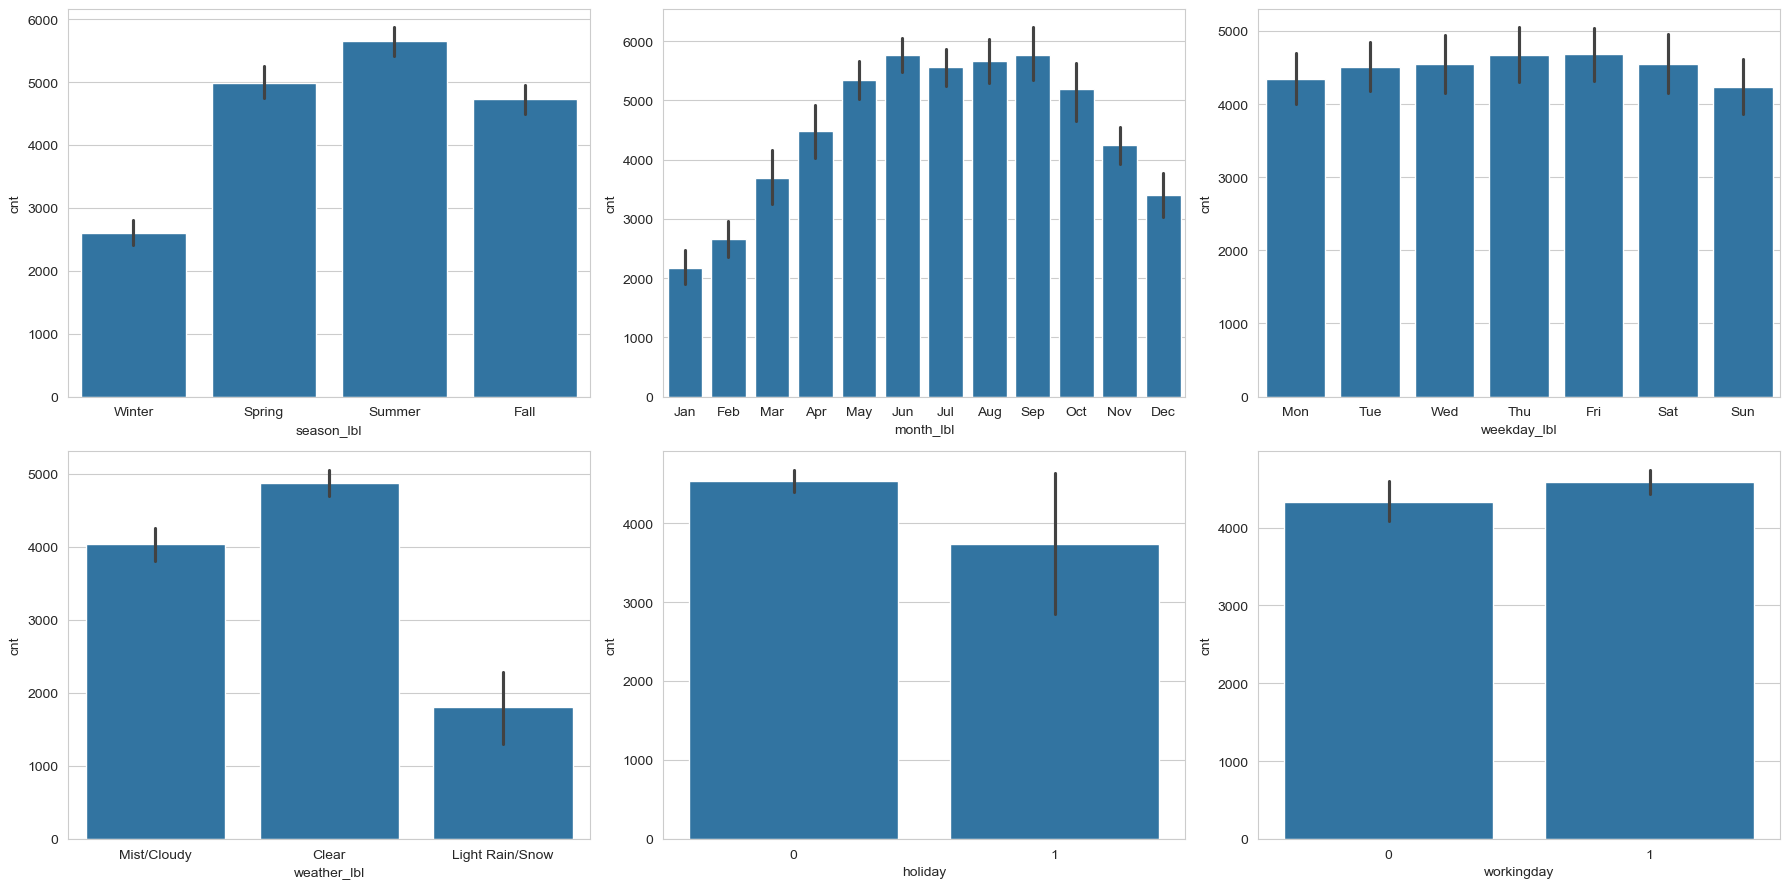

In [15]:
# Categorical features vs rentals
order_m = list(month_map.values())
order_w = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

fig, ax = plt.subplots(2, 3, figsize=(18, 9))
sns.barplot(data=df, x="season_lbl",  y="cnt", ax=ax[0,0], order=["Winter","Spring","Summer","Fall"])
sns.barplot(data=df, x="month_lbl",   y="cnt", ax=ax[0,1], order=order_m)
sns.barplot(data=df, x="weekday_lbl", y="cnt", ax=ax[0,2], order=order_w)
sns.barplot(data=df, x="weather_lbl", y="cnt", ax=ax[1,0])
sns.barplot(data=df, x="holiday",     y="cnt", ax=ax[1,1])
sns.barplot(data=df, x="workingday",  y="cnt", ax=ax[1,2])
plt.tight_layout()
plt.show()

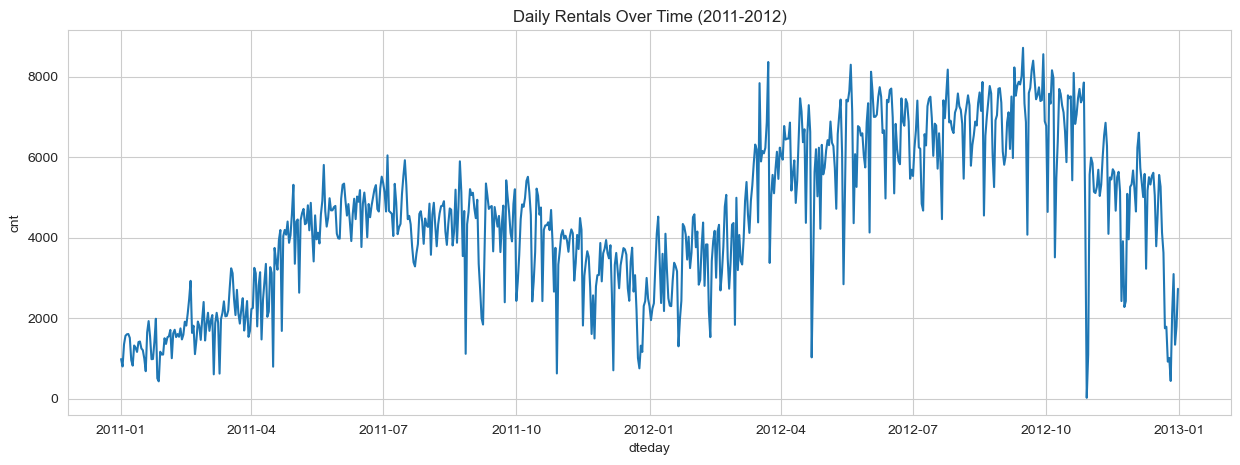

,mean,sum
year_lbl,,
2011,3405.761644,1243103
2012,5599.934426,2049576


In [16]:
# Trend over time
plt.figure(figsize=(15, 5))
sns.lineplot(data=df, x="dteday", y="cnt")
plt.title("Daily Rentals Over Time (2011-2012)")
plt.show()

df.groupby("year_lbl")["cnt"].agg(["mean", "sum"])

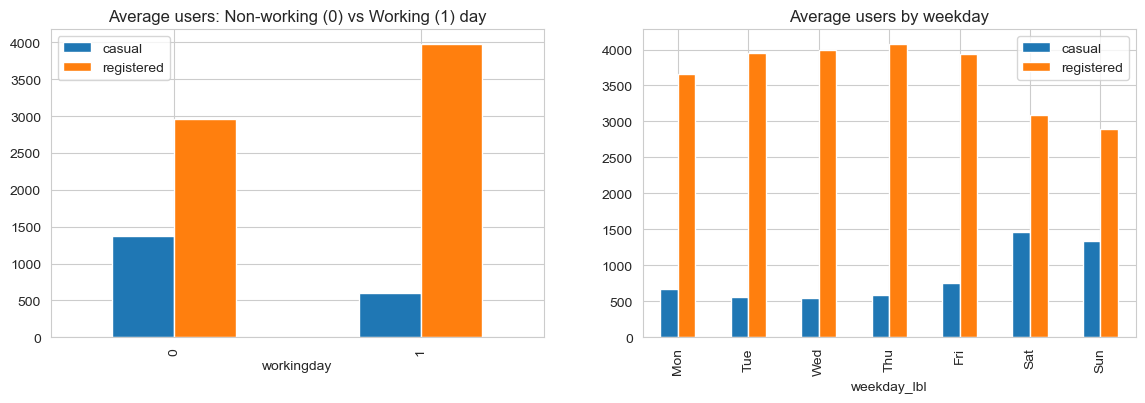

In [17]:
# Casual vs registered users
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
df.groupby("workingday")[["casual", "registered"]].mean().plot(kind="bar", ax=ax[0])
df.groupby("weekday_lbl")[["casual", "registered"]].mean().reindex(order_w).plot(kind="bar", ax=ax[1])
ax[0].set_title("Average users: Non-working (0) vs Working (1) day")
ax[1].set_title("Average users by weekday")
plt.show()

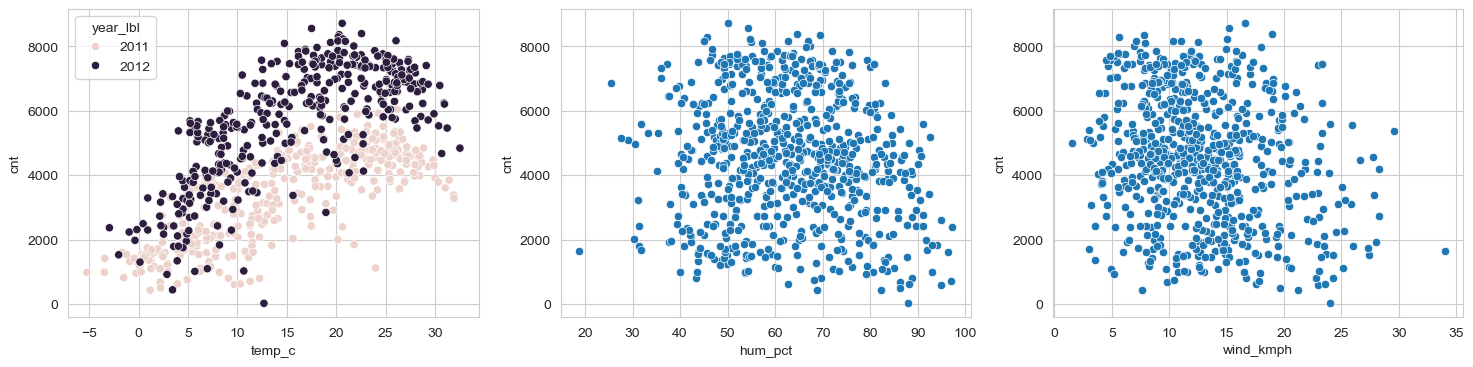

In [18]:
# Weather vs rentals (scatter plots)
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
sns.scatterplot(data=df, x="temp_c",    y="cnt", hue="year_lbl", ax=ax[0])
sns.scatterplot(data=df, x="hum_pct",   y="cnt", ax=ax[1])
sns.scatterplot(data=df, x="wind_kmph", y="cnt", ax=ax[2])
plt.show()

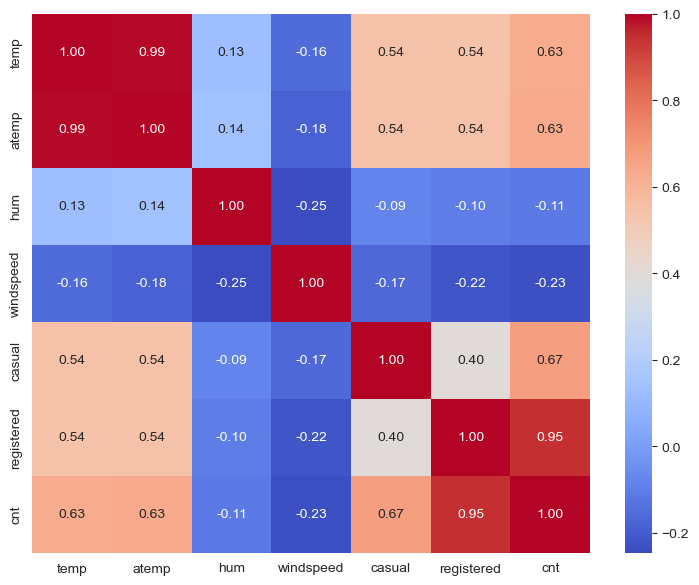

In [19]:
# Correlation heatmap
num_cols = ["temp", "atemp", "hum", "windspeed", "casual", "registered", "cnt"]
plt.figure(figsize=(9, 7))
sns.heatmap(df[num_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.show()

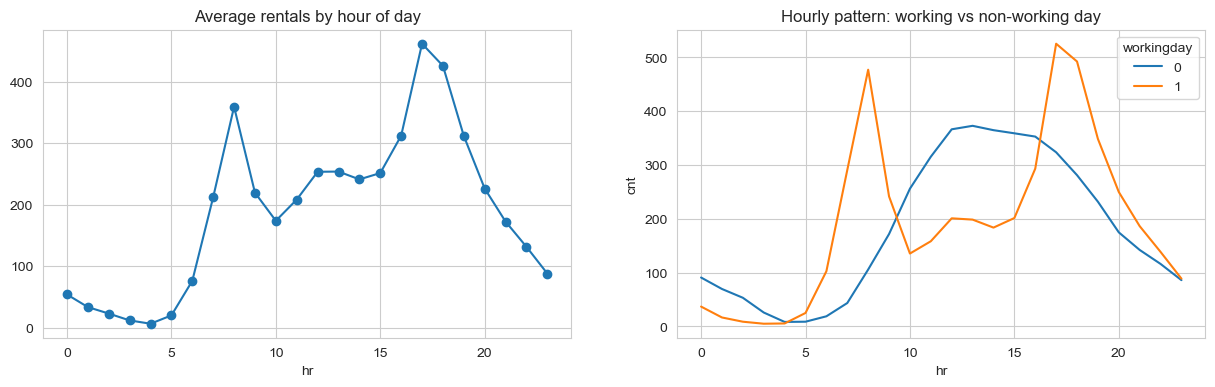

In [20]:
# Hourly pattern
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
hour.groupby("hr")["cnt"].mean().plot(ax=ax[0], marker="o")
ax[0].set_title("Average rentals by hour of day")

sns.lineplot(data=hour, x="hr", y="cnt", hue="workingday", errorbar=None, ax=ax[1])
ax[1].set_title("Hourly pattern: working vs non-working day")
plt.show()

# EDA Summary

## Key Findings from EDA
- Demand is strongly seasonal: highest in summer, lowest in winter.
- Rentals grew by about 64% from 2011 to 2012.
- Bad weather (rain/snow) reduces average rentals by more than 50%.
- Higher temperatures increase rentals; higher humidity and wind decrease them.
- Registered users dominate on working days; casual users rise on weekends and holidays.
- `temp` and `atemp` are almost perfectly correlated (multicollinearity).
- `casual + registered = cnt`, so both must be excluded from the model to avoid data leakage.
- One humidity reading of 0 (2011-03-10) was a sensor error and was imputed with the median.

# Feature Engineering, Modelling, Tuning, Comparison and Reports

In [21]:
# Feature engineering and selection
model_df = day.copy()      

model_df = model_df.drop(columns=["instant", "dteday", "casual", "registered", "atemp"])

median_hum = model_df.loc[model_df["hum"] != 0, "hum"].median()
model_df.loc[model_df["hum"] == 0, "hum"] = median_hum

cat_cols = ["season", "mnth", "weekday", "weathersit"]
model_df = pd.get_dummies(model_df, columns=cat_cols, drop_first=True, dtype=int)

print(model_df.shape)
model_df.head()

(731, 29)


,yr,holiday,workingday,temp,hum,windspeed,cnt,season_2,season_3,season_4,...,mnth_11,mnth_12,weekday_1,weekday_2,weekday_3,weekday_4,weekday_5,weekday_6,weathersit_2,weathersit_3
0,0,0,0,0.344167,0.805833,0.160446,985,0,0,0,...,0,0,0,0,0,0,0,1,1,0
1,0,0,0,0.363478,0.696087,0.248539,801,0,0,0,...,0,0,0,0,0,0,0,0,1,0
2,0,0,1,0.196364,0.437273,0.248309,1349,0,0,0,...,0,0,1,0,0,0,0,0,0,0
3,0,0,1,0.200000,0.590435,0.160296,1562,0,0,0,...,0,0,0,1,0,0,0,0,0,0
4,0,0,1,0.226957,0.436957,0.186900,1600,0,0,0,...,0,0,0,0,1,0,0,0,0,0


In [22]:
# Train/test split
from sklearn.model_selection import train_test_split

X = model_df.drop(columns=["cnt"])    
y = model_df["cnt"]                   

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (584, 28) | Test: (147, 28)


In [23]:
pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [24]:
# Build and compare multiple models
# 1.Imports and a helper function
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from sklearn.model_selection import KFold, cross_val_score, GridSearchCV
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import time

kf = KFold(n_splits=5, shuffle=True, random_state=42)
fitted = {}    
def evaluate(name, model, fit=True):
    """Train (optionally) and return all metrics for one model."""
    t0 = time.time()
    if fit:
        model.fit(X_train, y_train)
    fit_time = time.time() - t0
    fitted[name] = model

    pred_train = model.predict(X_train)
    pred_test  = model.predict(X_test)
    cv_r2 = cross_val_score(model, X_train, y_train, cv=kf, scoring="r2").mean()

    return {
        "Model": name,
        "Train R2": r2_score(y_train, pred_train),
        "Test R2":  r2_score(y_test, pred_test),
        "CV R2":    cv_r2,
        "RMSE":     np.sqrt(mean_squared_error(y_test, pred_test)),
        "MAE":      mean_absolute_error(y_test, pred_test),
        "Fit time (s)": fit_time,
    }

In [25]:
# Trained  all the  9 Models 
models = {
    "Linear Regression": Pipeline([("sc", StandardScaler()), ("m", LinearRegression())]),
    "Ridge":             Pipeline([("sc", StandardScaler()), ("m", Ridge(alpha=1.0))]),
    "Lasso":             Pipeline([("sc", StandardScaler()), ("m", Lasso(alpha=1.0))]),
    "KNN":               Pipeline([("sc", StandardScaler()), ("m", KNeighborsRegressor())]),
    "SVR":               Pipeline([("sc", StandardScaler()), ("m", SVR(C=1000))]),
    "Decision Tree":     DecisionTreeRegressor(random_state=42),
    "Random Forest":     RandomForestRegressor(random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
    "XGBoost":           XGBRegressor(random_state=42, verbosity=0),
}

results = [evaluate(name, m) for name, m in models.items()]
res_df = pd.DataFrame(results).sort_values("Test R2", ascending=False).reset_index(drop=True)
res_df.round(3)

,Model,Train R2,Test R2,CV R2,RMSE,MAE,Fit time (s)
0,Gradient Boosting,0.950,0.894,0.863,650.994,471.339,0.113
1,XGBoost,1.000,0.872,0.837,716.252,479.710,0.278
2,Random Forest,0.981,0.871,0.847,719.560,471.777,0.306
3,SVR,0.905,0.850,0.812,776.115,591.653,0.026
4,Ridge,0.847,0.840,0.821,800.173,586.384,0.006
5,Linear Regression,0.847,0.840,0.820,800.695,586.438,0.008
6,Lasso,0.847,0.840,0.821,801.287,587.441,0.007
7,Decision Tree,1.000,0.745,0.743,1011.390,649.333,0.005
8,KNN,0.673,0.585,0.475,1290.692,1096.439,0.004


# HyperParameter Tunning 

In [26]:
# Random Forest (takes about 1 minute)
rf_cv = GridSearchCV(
    RandomForestRegressor(random_state=42),
    {"n_estimators": [200, 400], "max_depth": [6, 10, None],
     "min_samples_split": [2, 5], "min_samples_leaf": [1, 3]},
    cv=5, scoring="r2", n_jobs=-1).fit(X_train, y_train)

# XGBoost
xgb_cv = GridSearchCV(
    XGBRegressor(random_state=42, verbosity=0),
    {"n_estimators": [200, 400], "max_depth": [3, 5],
     "learning_rate": [0.03, 0.1], "subsample": [0.8, 1.0]},
    cv=5, scoring="r2", n_jobs=-1).fit(X_train, y_train)

# Gradient Boosting
gb_cv = GridSearchCV(
    GradientBoostingRegressor(random_state=42),
    {"n_estimators": [200, 400], "max_depth": [2, 3],
     "learning_rate": [0.03, 0.1], "subsample": [0.8, 1.0]},
    cv=5, scoring="r2", n_jobs=-1).fit(X_train, y_train)

print("RF :", rf_cv.best_params_,  round(rf_cv.best_score_, 4))
print("XGB:", xgb_cv.best_params_, round(xgb_cv.best_score_, 4))
print("GB :", gb_cv.best_params_,  round(gb_cv.best_score_, 4))

RF : {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 400} 0.8424
XGB: {'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 400, 'subsample': 0.8} 0.8724
GB : {'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 200, 'subsample': 0.8} 0.8725


In [27]:
tuned = {"Tuned Random Forest": rf_cv.best_estimator_,
         "Tuned XGBoost": xgb_cv.best_estimator_,
         "Tuned Gradient Boosting": gb_cv.best_estimator_}

for name, m in tuned.items():
    results.append(evaluate(name, m, fit=False))   # already trained by GridSearch

res_df = pd.DataFrame(results).sort_values("CV R2", ascending=False).reset_index(drop=True)
res_df.round(3)

,Model,Train R2,Test R2,CV R2,RMSE,MAE,Fit time (s)
0,Tuned XGBoost,0.954,0.892,0.872,659.285,450.999,0.000
1,Tuned Gradient Boosting,0.941,0.889,0.869,666.976,471.654,0.000
2,Gradient Boosting,0.950,0.894,0.863,650.994,471.339,0.113
3,Tuned Random Forest,0.981,0.874,0.848,710.723,471.807,0.000
4,Random Forest,0.981,0.871,0.847,719.560,471.777,0.306
5,XGBoost,1.000,0.872,0.837,716.252,479.710,0.278
6,Lasso,0.847,0.840,0.821,801.287,587.441,0.007
7,Ridge,0.847,0.840,0.821,800.173,586.384,0.006
8,Linear Regression,0.847,0.840,0.820,800.695,586.438,0.008
9,SVR,0.905,0.850,0.812,776.115,591.653,0.026


# Model Comparison Report

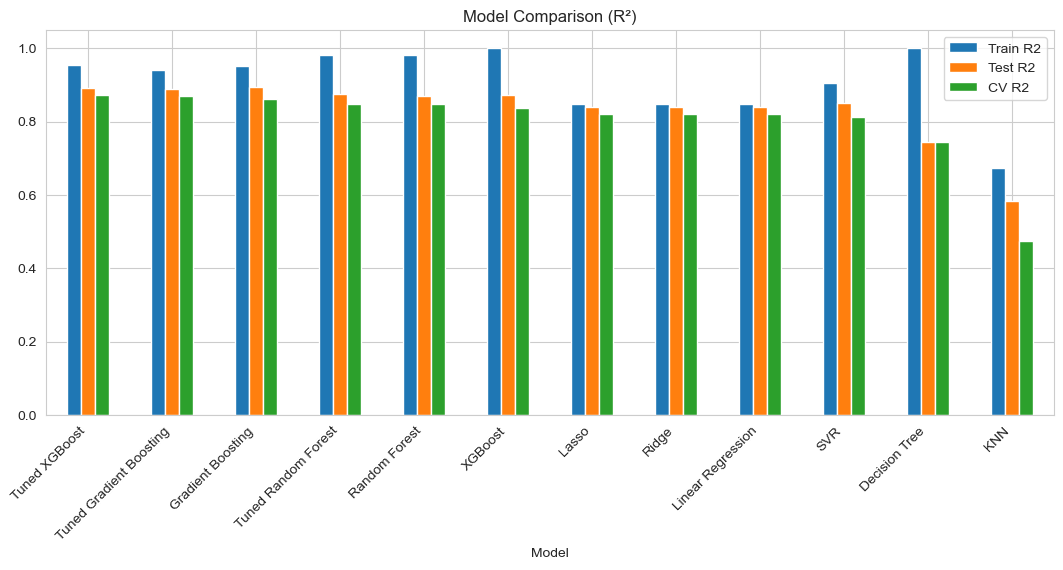

In [28]:
# 1.Comparison chart 
res_df.set_index("Model")[["Train R2", "Test R2", "CV R2"]].plot(kind="bar", figsize=(13, 5))
plt.title("Model Comparison (R²)")
plt.ylim(0, 1.05)
plt.xticks(rotation=45, ha="right")
plt.show()

Best model: Tuned XGBoost


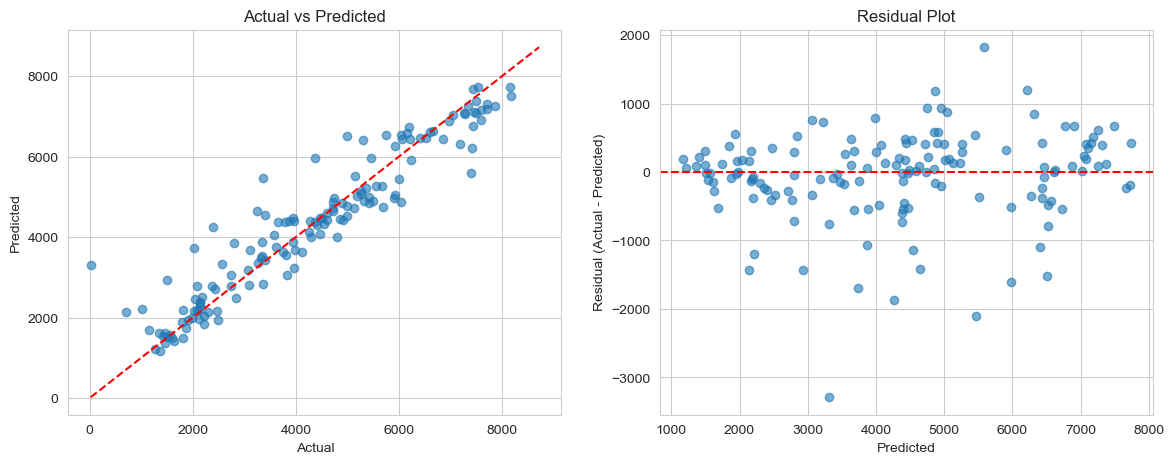

In [29]:
#2.Best model: actual vs predicted, and residuals
best_name  = res_df.loc[0, "Model"]
best_model = fitted[best_name]
pred = best_model.predict(X_test)
print("Best model:", best_name)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].scatter(y_test, pred, alpha=0.6)
ax[0].plot([y.min(), y.max()], [y.min(), y.max()], "r--")
ax[0].set_xlabel("Actual"); ax[0].set_ylabel("Predicted")
ax[0].set_title("Actual vs Predicted")

ax[1].scatter(pred, y_test - pred, alpha=0.6)
ax[1].axhline(0, color="r", linestyle="--")
ax[1].set_xlabel("Predicted"); ax[1].set_ylabel("Residual (Actual - Predicted)")
ax[1].set_title("Residual Plot")
plt.show()

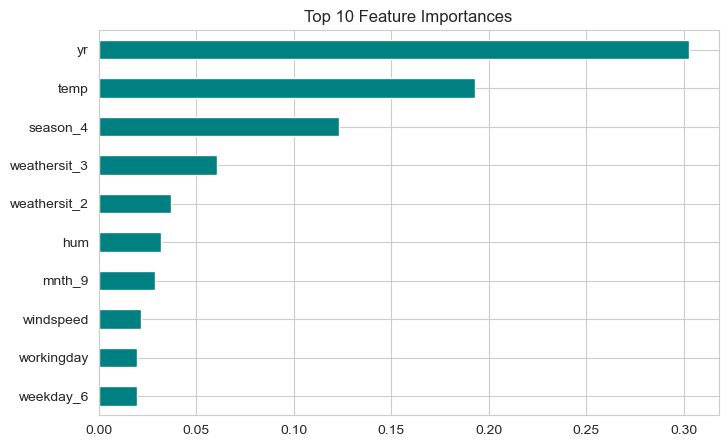

In [30]:
# 3.Feature Importaance
imp = pd.Series(best_model.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
imp.sort_values().plot(kind="barh", figsize=(8, 5), color="teal")
plt.title("Top 10 Feature Importances")
plt.show()


In [31]:
# A reality check: time-based split
from sklearn.base import clone

cut = int(len(model_df) * 0.8)            # day.csv is already sorted by date
X_tr_t, X_te_t = X.iloc[:cut], X.iloc[cut:]
y_tr_t, y_te_t = y.iloc[:cut], y.iloc[cut:]

time_rows = []
for name in ["Ridge", "Tuned Random Forest", "Tuned XGBoost", "Tuned Gradient Boosting"]:
    m = clone(fitted[name]).fit(X_tr_t, y_tr_t)
    p = m.predict(X_te_t)
    time_rows.append({"Model": name,
                      "R2 (time split)": r2_score(y_te_t, p),
                      "RMSE (time split)": np.sqrt(mean_squared_error(y_te_t, p))})

pd.DataFrame(time_rows).round(3)

,Model,R2 (time split),RMSE (time split)
0,Ridge,0.653,1103.608
1,Tuned Random Forest,0.497,1329.694
2,Tuned XGBoost,0.627,1144.482
3,Tuned Gradient Boosting,0.732,971.357


In [32]:
import joblib
joblib.dump(best_model, "best_bike_rental_model.pkl")

['best_bike_rental_model.pkl']

## Model Comparison Report

### Models evaluated
Linear Regression, Ridge, Lasso, KNN, SVR, Decision Tree, Random Forest,
Gradient Boosting and XGBoost, plus tuned versions of the last three.
Metrics: R², RMSE, MAE and 5-fold cross-validated R².

### Results
(paste the res_df table here, or describe the top 3)

### Observations
- **Best models:** tuned XGBoost and tuned Gradient Boosting (CV R² about 0.87,
  test R² about 0.89, MAE about 450-470 bikes/day).
- **Overfitting:** Decision Tree and untuned XGBoost had Train R² = 1.00 but lower
  test scores. Tuning reduced XGBoost's gap.
- **Linear models** were stable (about 0.84) but cannot capture non-linear weather effects.
- **KNN** performed worst (small data, many dummy columns).
- **Time-based check:** performance on the future-most 20% of days was lower
  (R² about 0.5-0.7), so the random-split score is optimistic.

### Recommendation for production
Gradient Boosting (tuned), or XGBoost as an equal alternative.
Reasons: highest cross-validated accuracy, small gap between train and test,
fast training (under a second), and the best result in the time-based check.
Retrain regularly (e.g. monthly) because demand grows over time.

### Key drivers
Temperature, year (growth), humidity, season and wind speed.

## Report on Challenges Faced

| # | Challenge | Technique used | Reasoning |
|---|---|---|---|
| 1 | Season labels in the Readme conflicted with the data (season 1 contains Dec-Mar) | Checked months per season and labelled season 1 as Winter | Wrong labels would give wrong EDA conclusions |
| 2 | The Readme and assignment disagree on the temperature scaling (divide by 41 vs min -8 / max 39) | Used the assignment's formula, temp x 47 - 8 | The formula divides by 41 would put the coldest hour of two winters at about 0.8 C, which is implausible for Washington D.C. Only used for EDA; models use the normalized values |
| 3 | Data leakage: cnt = casual + registered | Dropped both columns | They would give a fake near-perfect score and are unknown at prediction time |
| 4 | Multicollinearity: temp vs atemp (r = 0.99) | Dropped atemp | Removes redundancy and stabilizes linear models |
| 5 | Humidity = 0 on 2011-03-10 (sensor failure; 22 zero hours in hourly data) | Replaced with the median humidity | 0% humidity is impossible; the median is robust |
| 6 | Categorical variables stored as numbers | One-hot encoding (drop_first=True) | Prevents false ordering (month 12 > month 1) and the dummy variable trap |
| 7 | Features on different scales | StandardScaler inside Pipelines for linear, KNN and SVR | These models are scale-sensitive; the pipeline avoids test-data leakage |
| 8 | Overfitting (Decision Tree and untuned XGBoost, train R2 = 1.0) | Cross-validation, ensembles, hyperparameter tuning | Better generalization to unseen data |
| 9 | Small dataset (731 rows) makes single test scores noisy | Used 5-fold CV and compared models by CV R2 | A more reliable estimate than one 147-row test set |
| 10 | Time-ordered data with a random split can look too good | Added a time-based split check | Shows the honest, lower performance when predicting the future |
| 11 | Outliers in windspeed and humidity | Inspected with boxplots and kept them | They are real weather events; tree models are robust to them |